In [1]:
# want to check the resume is appropirate or not 

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
import re

In [2]:
df = pd.read_csv('resumeDetails.csv')
print(df)

         Category                                             Resume
0    Data Science  Skills * Programming Languages: Python (pandas...
1    Data Science  Education Details \r\nMay 2013 to May 2017 B.E...
2    Data Science  Areas of Interest Deep Learning, Control Syste...
3    Data Science  Skills â¢ R â¢ Python â¢ SAP HANA â¢ Table...
4    Data Science  Education Details \r\n MCA   YMCAUST,  Faridab...
..            ...                                                ...
957       Testing  Computer Skills: â¢ Proficient in MS office (...
958       Testing  â Willingness to accept the challenges. â ...
959       Testing  PERSONAL SKILLS â¢ Quick learner, â¢ Eagerne...
960       Testing  COMPUTER SKILLS & SOFTWARE KNOWLEDGE MS-Power ...
961       Testing  Skill Set OS Windows XP/7/8/8.1/10 Database MY...

[962 rows x 2 columns]


In [3]:
# check the first 5 values 
print(df.head())

       Category                                             Resume
0  Data Science  Skills * Programming Languages: Python (pandas...
1  Data Science  Education Details \r\nMay 2013 to May 2017 B.E...
2  Data Science  Areas of Interest Deep Learning, Control Syste...
3  Data Science  Skills â¢ R â¢ Python â¢ SAP HANA â¢ Table...
4  Data Science  Education Details \r\n MCA   YMCAUST,  Faridab...


In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 962 entries, 0 to 961
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  962 non-null    object
 1   Resume    962 non-null    object
dtypes: object(2)
memory usage: 15.2+ KB
None


In [5]:
# want to check the unique values 
print(df['Category'].unique())

['Data Science' 'HR' 'Advocate' 'Arts' 'Web Designing'
 'Mechanical Engineer' 'Sales' 'Health and fitness' 'Civil Engineer'
 'Java Developer' 'Business Analyst' 'SAP Developer' 'Automation Testing'
 'Electrical Engineering' 'Operations Manager' 'Python Developer'
 'DevOps Engineer' 'Network Security Engineer' 'PMO' 'Database' 'Hadoop'
 'ETL Developer' 'DotNet Developer' 'Blockchain' 'Testing']


In [6]:
# to check total no. of rows and columns 
print(df.shape)

(962, 2)


In [7]:
# value count of the total rows 
print(df['Category'].value_counts())

Category
Java Developer               84
Testing                      70
DevOps Engineer              55
Python Developer             48
Web Designing                45
HR                           44
Hadoop                       42
Sales                        40
Data Science                 40
Mechanical Engineer          40
ETL Developer                40
Blockchain                   40
Operations Manager           40
Arts                         36
Database                     33
Health and fitness           30
PMO                          30
Electrical Engineering       30
Business Analyst             28
DotNet Developer             28
Automation Testing           26
Network Security Engineer    25
Civil Engineer               24
SAP Developer                24
Advocate                     20
Name: count, dtype: int64


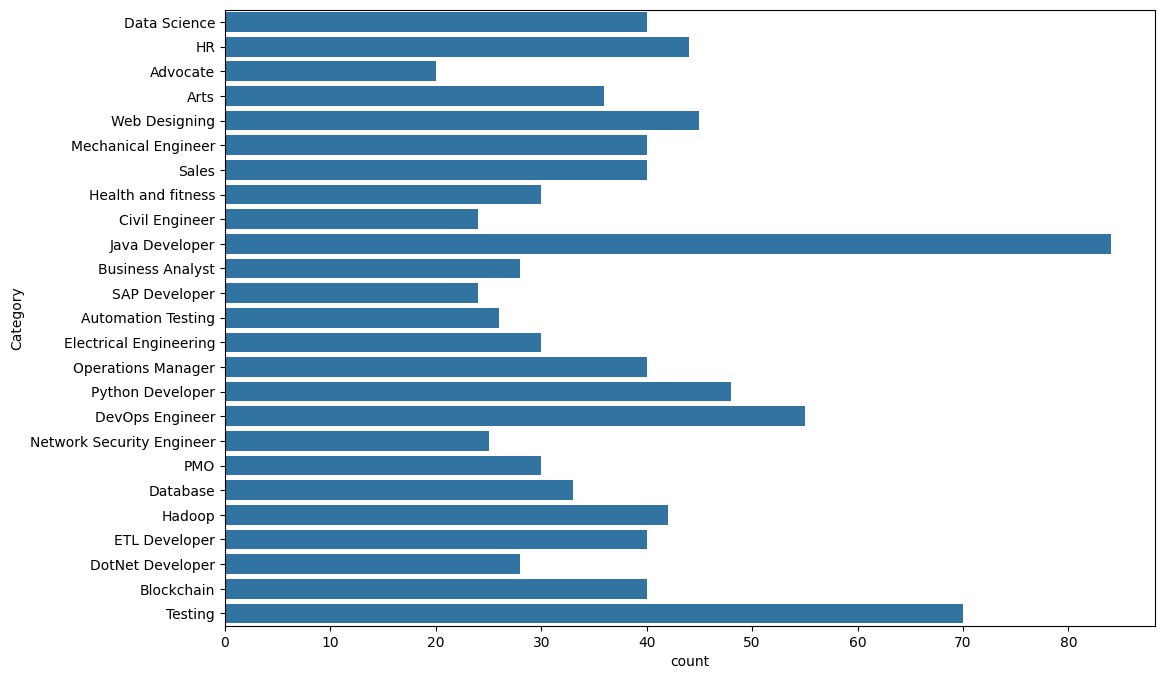

In [8]:
# want to show these details on the countplot chart 
plt.figure(figsize=(12, 8))
sns.countplot(df['Category'])
plt.show()

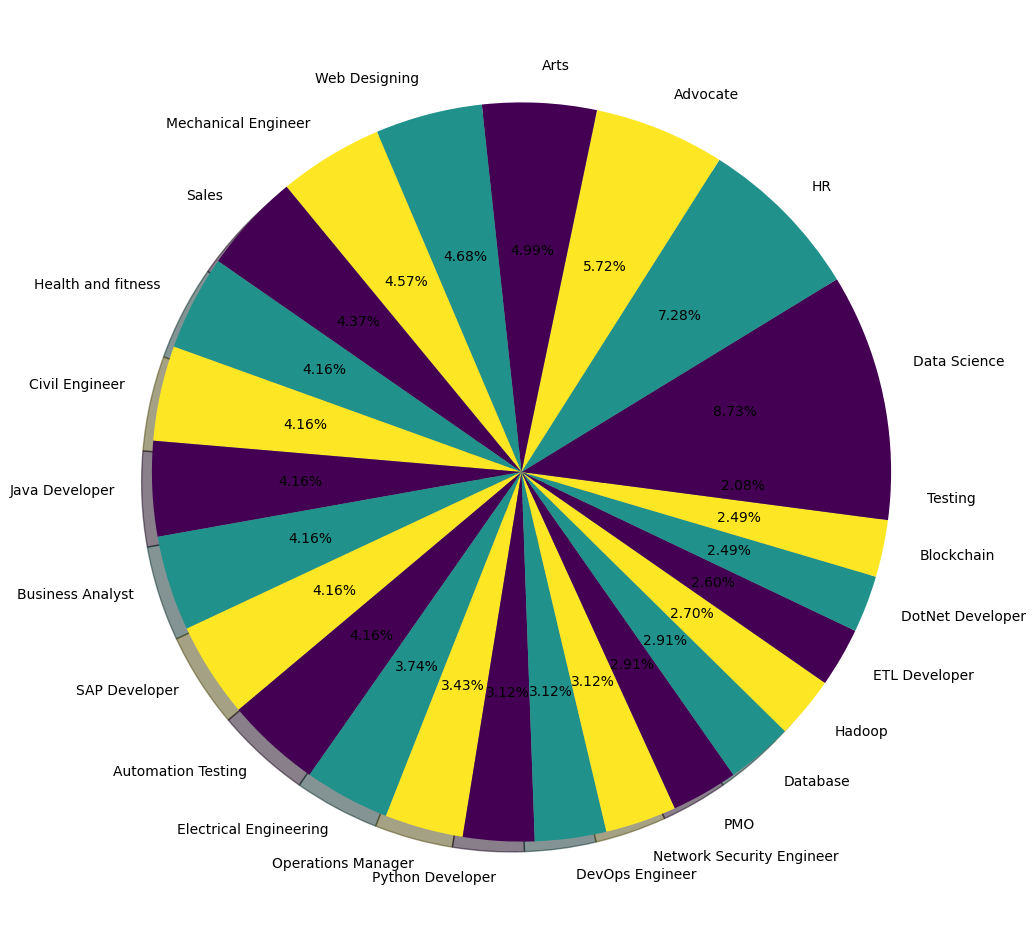

In [9]:
# want to draw the data of categories in the form of pie chart 
# value and labels 
plt.figure(figsize=(12, 12))
value = df['Category'].value_counts()
labels = df['Category'].unique()
# print(labels) color range - start, end, 3  (0 -green , 0.5 - white , 1 - blue - color pallete)
plt.pie(value, labels=labels,autopct='%1.2f%%',shadow=True,colors=plt.cm.viridis(np.linspace(0,1,3)))
plt.show()

In [10]:
# want to perform label encoding so that we can conver the text into the number 
from sklearn.preprocessing import LabelEncoder
print(df['Category'].unique())
leObj = LabelEncoder()
leObj.fit(df["Category"]) 
df['Category'] = leObj.transform(df["Category"])

['Data Science' 'HR' 'Advocate' 'Arts' 'Web Designing'
 'Mechanical Engineer' 'Sales' 'Health and fitness' 'Civil Engineer'
 'Java Developer' 'Business Analyst' 'SAP Developer' 'Automation Testing'
 'Electrical Engineering' 'Operations Manager' 'Python Developer'
 'DevOps Engineer' 'Network Security Engineer' 'PMO' 'Database' 'Hadoop'
 'ETL Developer' 'DotNet Developer' 'Blockchain' 'Testing']


In [11]:
print(df['Category'].unique())
# sklearn - 

[ 6 12  0  1 24 16 22 14  5 15  4 21  2 11 18 20  8 17 19  7 13 10  9  3
 23]


In [12]:
# # import re - regurlar expression 
# # text clearn - https, emojis, @, stopwords, \n\c, ^$#&

# # pandas - apply() - lambda - single line function - variables - cleaning 
# def cleanData(txt): 
#     cleantxt = re.sub('http\S+\s','',txt) # used to remove the http link or text
#     return cleantxt

# # \ - forward slash
# # / - backward slash 

# # state = "My name is kartik and website link is http://www.kartik.com use for calculation"
# documentsval = [
#     "My name is kartik and website link is http://www.kartik.com use for calculation",
#     "alok is great prime minister", 
#     "india is a great country", 
#     "delhi is a great city"
# ]
# valdata = pd.DataFrame(documentsval)
# # print(valdata)

# print(valdata[0])

# valdata[0] = valdata[0].apply(lambda x: cleanData(x))
# print(valdata[0])

In [13]:
def cleanData(txt): 
    cleantxt = re.sub('http\S+\s','',txt) # it will used to remove the https text 
    cleantxt = re.sub('@\S+','', cleantxt) # it will used to remove the @ and email address
    cleantxt = re.sub('#\S+\s','', cleantxt) # it will used to remove the # and #1232 associated values 
    cleantxt = re.sub('RT|cc','', cleantxt) # it will used to remove the RT and cc associated values 
    cleantxt = re.sub('\s+','', cleantxt) # it will used to remove the sequence like \n, \t, etc  
    cleantxt = re.sub('[%s]'% re.escape(""" !"#$%&'()*+,-./:;<=>?@[\]^_'â¢{|}~"""),'', cleantxt) # it will used to remove the special characters values 
    return cleantxt

df["Resume"] = df["Resume"].apply(lambda x: cleanData(x))

<>:2: SyntaxWarning: invalid escape sequence '\S'
<>:3: SyntaxWarning: invalid escape sequence '\S'
<>:4: SyntaxWarning: invalid escape sequence '\S'
<>:6: SyntaxWarning: invalid escape sequence '\s'
<>:7: SyntaxWarning: invalid escape sequence '\]'
<>:2: SyntaxWarning: invalid escape sequence '\S'
<>:3: SyntaxWarning: invalid escape sequence '\S'
<>:4: SyntaxWarning: invalid escape sequence '\S'
<>:6: SyntaxWarning: invalid escape sequence '\s'
<>:7: SyntaxWarning: invalid escape sequence '\]'
C:\Users\Admin\AppData\Local\Temp\ipykernel_2160\548073856.py:2: SyntaxWarning: invalid escape sequence '\S'
  cleantxt = re.sub('http\S+\s','',txt) # it will used to remove the https text
C:\Users\Admin\AppData\Local\Temp\ipykernel_2160\548073856.py:3: SyntaxWarning: invalid escape sequence '\S'
  cleantxt = re.sub('@\S+','', cleantxt) # it will used to remove the @ and email address
C:\Users\Admin\AppData\Local\Temp\ipykernel_2160\548073856.py:4: SyntaxWarning: invalid escape sequence '\S'
  c

In [16]:
df['Resume'] = df['Resume'].apply(lambda val: val.lower())
print(df['Resume'])

0      skillsprogramminglanguagespythonpandasnumpysci...
1      educationdetailsmay2013tomay2017beuitrgpvdatas...
2      areasofinterestdeeplearningcontrolsystemdesign...
3      skillsrpythonsaphanatableausaphanasqlsaphanapa...
4      educationdetailsmcaymcaustfaridabadharyanadata...
                             ...                        
957    computerskillsproficientinmsofficewordbasicexc...
958    willingnesstoaeptthechallengespositivethinking...
959    personalskillsquicklearnereagernesstolearnnewt...
960    computerskillssoftwareknowledgemspowerpointmso...
961    skillsetoswindowsxp788110databasemysqlsqlserve...
Name: Resume, Length: 962, dtype: object


In [ ]:
# here we are converting the text into the numbers and now we will convert the text into the vocabulary or count 
from sklearn.feature_extraction.text import TfidfVectorizer 
tfidf = TfidfVectorizer(stop_words="english") # we have create an object and informing them about the english stopwords
tfidf.fit(df['Resume'])
# print(userde)
requiredText = tfidf.transform(df['Resume'])

In [21]:
print(requiredText)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 3837 stored elements and shape (962, 665)>
  Coords	Values
  (0, 483)	0.5773502691896258
  (0, 587)	0.5773502691896258
  (0, 588)	0.5773502691896258
  (1, 170)	1.0
  (2, 25)	1.0
  (3, 485)	1.0
  (4, 173)	1.0
  (5, 468)	1.0
  (6, 484)	1.0
  (7, 143)	0.25
  (7, 271)	0.5
  (7, 352)	0.5
  (7, 435)	0.25
  (7, 436)	0.25
  (7, 488)	0.25
  (7, 489)	0.5
  (8, 5)	0.5773502691896258
  (8, 246)	0.5773502691896258
  (8, 381)	0.5773502691896258
  (9, 33)	0.2182178902359924
  (9, 35)	0.2182178902359924
  (9, 41)	0.2182178902359924
  (9, 44)	0.2182178902359924
  (9, 98)	0.2182178902359924
  (9, 99)	0.2182178902359924
  :	:
  (947, 476)	1.0
  (948, 229)	1.0
  (949, 56)	1.0
  (950, 59)	1.0
  (951, 497)	0.408248290463863
  (951, 519)	0.408248290463863
  (951, 568)	0.408248290463863
  (951, 594)	0.408248290463863
  (951, 609)	0.408248290463863
  (951, 613)	0.408248290463863
  (952, 384)	1.0
  (953, 60)	1.0
  (954, 476)	1.0
  (955, 229)	1.0
  (9

In [22]:
# we will split the data into the training and testing phase 

from sklearn.model_selection import train_test_split 
# requiredText is a variable used to store the converted values from text to number
X_train, X_test, y_train, y_test = train_test_split(requiredText,df['Category'], test_size=0.20, random_state=42)

In [ ]:
print(X_train.shape)
# print(X_train)
print(X_test.shape)
# print(X_test)

(769, 665)
(193, 665)
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 653 stored elements and shape (193, 665)>
  Coords	Values
  (0, 543)	1.0
  (1, 546)	1.0
  (2, 151)	1.0
  (3, 473)	1.0
  (4, 147)	1.0
  (5, 20)	0.1924500897298752
  (5, 39)	0.1924500897298752
  (5, 45)	0.1924500897298752
  (5, 71)	0.1924500897298752
  (5, 72)	0.1924500897298752
  (5, 182)	0.1924500897298752
  (5, 200)	0.1924500897298752
  (5, 206)	0.1924500897298752
  (5, 207)	0.1924500897298752
  (5, 208)	0.1924500897298752
  (5, 210)	0.1924500897298752
  (5, 258)	0.1924500897298752
  (5, 270)	0.1924500897298752
  (5, 273)	0.1924500897298752
  (5, 285)	0.1924500897298752
  (5, 356)	0.1924500897298752
  (5, 367)	0.1924500897298752
  (5, 396)	0.1924500897298752
  (5, 403)	0.1924500897298752
  (5, 412)	0.1924500897298752
  :	:
  (184, 34)	0.33333333333333337
  (184, 130)	0.33333333333333337
  (184, 244)	0.33333333333333337
  (184, 332)	0.33333333333333337
  (184, 354)	0.33333333333333337
  (184, 355)	0.333

In [26]:
from sklearn.naive_bayes import MultinomialNB # import MultinomialNB 
from sklearn.metrics import accuracy_score # import accuracy_score so that we can find the accuracy of the metrics 

# create an object of the MultinomialNB 
nb_model = MultinomialNB()

In [27]:
# now we will pass the X_train and y_train to the MultinomialNB object 
nb_model.fit(X_train, y_train)  # here we are creating a multinomialNB for the given model 

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [37]:
# now we will check the prediction for the countVectorizer in Bag of Words 
prediction_NB = nb_model.predict(X_test)

In [38]:
# accuracy_score() function will be used for prediction 
print(accuracy_score(y_test,prediction_NB)) # the accuracy comes at 0.9222

0.9222797927461139


In [ ]:
# ----------------------------- Logistic Regression ------------------------------------

In [33]:
# now we will make an algorithm to predict the values 
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [34]:
# prediction for logistic regression 
predicted_value_LR = logistic_model.predict(X_test)


In [ ]:
# to find the accuracy score for logistic regression 
print(accuracy_score(y_test, predicted_value_LR)) # 0.96

0.9689119170984456


In [36]:
print(predicted_value_LR)

[15 15 15 13 14 17 16  2 15 14 13 12 16 23 20  5  6  4 10  9 19  1 10 23
 23  6 22 22  2 12 18  1  8 24 11 23  7 12 24  8 18  6  8 19 24 23 21  1
 15  4 15 22 11  5 15 13  1 19  5 12 22 22 20 24 21 18 12 10 10 20 10  8
  9 21 17 21  0 17 16 14 15 11 11  8 20  3 19  8 15  2  9 10  2 23 20 20
 23 12 18 12  7 16  8 14 18  3 14 19 14 14 15 18  8  2 21 18 23 10 23 15
 11 15 12  3 15  3  7 12 19  8 20 15  3 15  9 19  1 23 21  5 20 15 16  7
  7  8 15 18  1 15 13 20  7  4 18 11 15 15  5 12  9 22 18 21  8 23  4 12
 24 16 15 22  8 22  3 16 23 23 12  7 16 18  5  3 18  8 23 23 20  6  6  7
 23]


In [39]:
print(prediction_NB)

[15 15 15 13 14 17 16  2 15 14 13 12 16 23 20  5  6  4 10  9 19  1 10 23
 23  6 22 22  2 12 18  1  8 24 11 23  7 12 24  8 18  6  8 19 24 23 21  1
 15  4 15 22 11  5 15 13  1 19 15 12 22 22 20 24 15 18 12 10 10 20 10  8
  9 21 17 21 15 17 16 14 15 11 11  8 20  3 19  8 15  2  9 10  2 23 20 20
 23 12 18 12  7 16  8 14 18  3 14 19 14 14 15 18  8  2 21 18 23 10 23 15
 11 15 12  3 15  3 15 12 19  8 20 15  3 15  9 19  1 23 21 15 20 15 16 15
  7  8 15 18  1 15 13 20  7  4 18 11 15 15 15 12  9 22 18 15  8 23  4 12
 24 16 15 22  8 22  3 16 23 23 12  7 16 18 15  3 18  8 23 23 20  6  6  7
 23]
